# District network from LDA topic weights + stochastic block model (SBM)

**Network.** Nodes = school districts (LEAIDs) with at least `MIN_MEETINGS` meetings in `YEAR`. Each district's node
attribute is its topic profile: the mean of its meetings' LDA topic weights (equal weight per meeting), from
`output/lda_cleaned/<TAG>/theta_meetings_k<K>.parquet` (written by `source/analysis/lda_cleaned/run_lda.py`).
Every pair of districts is joined by an edge whose value is the **Euclidean distance** between their topic profiles,
so the network is complete and weighted (small distance = similar agendas).

**Model.** A stochastic block model assigns each district to one of `Q` latent blocks; the distribution of an edge depends
only on the blocks of its two endpoints.
- **Main fit — weighted (Gaussian) SBM on the distances:** `d_ij ~ Normal(μ[z_i, z_j], σ²)`, a common variance σ² and one
  mean per block pair. Fitting maximises the profile log-likelihood (μ, σ² at their MLEs) over memberships by greedy
  single-node moves from several k-means starts.
- **Comparison — Bernoulli SBM on a k-nearest-neighbour graph:** keep an (unweighted) edge between two districts if either is
  among the other's `KNN` closest districts; `A_ij ~ Bernoulli(p[z_i, z_j])`. This is the classic binary SBM.
- **Number of blocks** chosen by ICL (integrated classification likelihood; Daudin, Picard & Robin 2008):
  `ICL = logL + Σ_a n_a log(n_a/n) − (P/2)·log(#pairs) − ((Q−1)/2)·log n`, with `P` = number of edge parameters.

No network package is needed (graph-tool / networkx / graspologic are not installed); the SBM code is in the next
section, about 60 lines of numpy.

**Caveats (read before interpreting).**
- Pairwise distances among points in topic space are not independent (they obey the triangle inequality), but the SBM
  likelihood treats them as independent. The weighted SBM is therefore best read as a *clustering of districts by how they
  relate to everyone else*, not as a generative model of the data; ICL tends to favour more blocks than the data justify.
- With the partial upload, most districts have only 1–2 meetings in 2022, so their profiles are noisy. Raise
  `MIN_MEETINGS` (e.g. to 5) once the full data are in.
- Euclidean distance on raw topic shares is dominated by the big topics (procedural, conversational). The block profiles
  in section 4 show which topics actually separate the blocks.

In [1]:
from pathlib import Path
import os, time
import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
from scipy.spatial.distance import pdist, squareform
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score
from IPython.display import display

REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "globals.json").exists())
os.chdir(REPO)

TAG, K, YEAR = "y2022", 15, 2022  # LDA run folder, number of topics, year of the network
MIN_MEETINGS = 1        # districts need at least this many meetings in YEAR (raise to ~5 with the full data)
Q_RANGE = range(1, 9)   # numbers of blocks to try
N_STARTS = 5            # k-means starts per Q (best log-likelihood kept)
KNN = 10                # neighbours per district for the binary comparison graph
SEED = 236

RES = Path("output/lda_cleaned") / TAG
WORK = Path("Datastore/DistrictView/derived/lda_cleaned") / TAG
FIG = RES / "figures"
FIG.mkdir(parents=True, exist_ok=True)

BLUE, BLUE_LIGHT, GRAY, INK, MUTED, GRID = "#2a78d6", "#9ec5f4", "#c3c2b7", "#0b0b0b", "#52514e", "#e1e0d9"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": GRAY, "axes.labelcolor": MUTED,
    "xtick.color": MUTED, "ytick.color": MUTED, "text.color": INK, "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": GRID, "grid.linewidth": .6, "axes.axisbelow": True, "font.size": 10,
})

## 1. Build the district network

2022: 714 districts with >= 1 meeting(s) (714 with any); 254,541 edges
Meetings per district: median 1, max 16


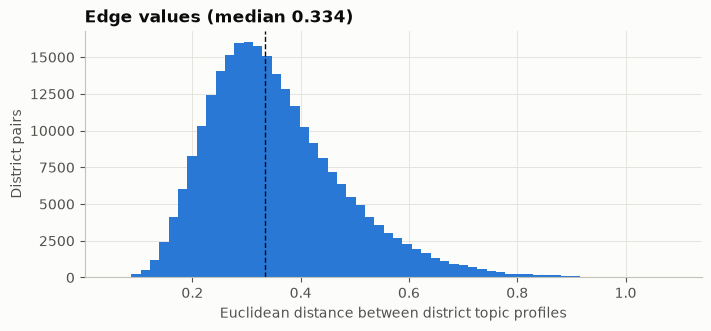

In [2]:
T = [f"t{i}" for i in range(1, K + 1)]
meetings = pd.read_parquet(RES / f"theta_meetings_k{K}.parquet")
meetings = meetings.loc[meetings.year == YEAR]
n_meet = meetings.groupby("leaid").size()
profiles = meetings.groupby("leaid")[T].mean()           # equal weight per meeting
profiles = profiles.loc[n_meet[n_meet >= MIN_MEETINGS].index]
X = profiles.values
D = squareform(pdist(X, metric="euclidean"))             # n x n edge values, zero diagonal
n = len(profiles)
print(f"{YEAR}: {n:,} districts with >= {MIN_MEETINGS} meeting(s) ({len(n_meet):,} with any); "
      f"{n * (n - 1) // 2:,} edges")
print(f"Meetings per district: median {n_meet.loc[profiles.index].median():.0f}, max {n_meet.max()}")

# Short topic labels: top 3 distinctive words (LDAvis relevance, lambda = 0.6), as in lda_weights.ipynb.
vec = joblib.load(WORK / "vectorizer.joblib")
model = joblib.load(WORK / f"lda_k{K}.joblib")
words = vec.get_feature_names_out()
beta = model.components_ / model.components_.sum(axis=1, keepdims=True)
share = (meetings[T].mul(meetings.modeled_tokens, axis=0).sum() / meetings.modeled_tokens.sum()).values
relevance = .6 * np.log(beta) + .4 * np.log(beta / (share @ beta))
LABEL = {t: f"{t} · " + ", ".join(words[np.argsort(r)[::-1][:3]]) for t, r in zip(T, relevance)}

fig, ax = plt.subplots(figsize=(7, 3.2), layout="constrained")
d = D[np.triu_indices(n, 1)]
ax.hist(d, bins=60, color=BLUE)
ax.axvline(np.median(d), color=INK, lw=1, ls="--")
ax.set(xlabel="Euclidean distance between district topic profiles", ylabel="District pairs",
       title=f"Edge values (median {np.median(d):.3f})")
fig.savefig(FIG / f"network_distances_k{K}_{YEAR}.png", dpi=160)
plt.show()

## 2. SBM fitting code

`fit_sbm` keeps block-pair sufficient statistics (sum of edge values, sum of squares, number of pairs) and moves one node
at a time to the block that most increases the profile log-likelihood, until a full sweep makes no move. Each node's
row sums per block are cached so a move costs O(n + Q²) rather than recomputing everything.

In [3]:
def _block_sums(R, Z):
    """Unordered-pair block sums from per-node block row sums R = M @ Z."""
    U = Z.T @ R
    U[np.diag_indices_from(U)] /= 2
    return U

def _shift(U, r, a, sign):
    """Add (sign=+1) or remove (sign=-1) a node with per-block sums r to/from block a."""
    U = U.copy()
    U[a, :] += sign * r
    U[:, a] += sign * r
    U[a, a] -= sign * r[a]
    return U

def loglik(S1, S2, N, family):
    iu = np.triu_indices_from(N)
    s1, s2, m = S1[iu], S2[iu], N[iu]
    ok = m > 0
    s1, s2, m = s1[ok], s2[ok], m[ok]
    if family == "gaussian":   # common variance; block-pair means at their MLE
        sigma2 = max((s2.sum() - (s1 ** 2 / m).sum()) / m.sum(), 1e-12)
        return -.5 * m.sum() * (np.log(2 * np.pi * sigma2) + 1)
    p = np.clip(s1 / m, 1e-12, 1 - 1e-12)   # bernoulli
    return float(np.sum(s1 * np.log(p) + (m - s1) * np.log(1 - p)))

def fit_sbm(M, z0, family, max_sweeps=100, seed=SEED):
    """Greedy profile-likelihood SBM fit from initial labels z0. M: symmetric edge values, zero diagonal."""
    rng = np.random.default_rng(seed)
    z = np.unique(z0, return_inverse=True)[1]
    Q, n = z.max() + 1, len(z)
    M2 = M ** 2
    Z = np.eye(Q)[z]
    R1, R2 = M @ Z, M2 @ Z
    counts = Z.sum(axis=0)
    S1, S2 = _block_sums(R1, Z), _block_sums(R2, Z)
    N = np.outer(counts, counts)
    N[np.diag_indices(Q)] = counts * (counts - 1) / 2
    best = loglik(S1, S2, N, family)
    for sweep in range(max_sweeps):
        moved = 0
        for i in rng.permutation(n):
            a = z[i]
            if counts[a] == 1:
                continue   # keep every block non-empty
            rc = counts.copy()
            rc[a] -= 1
            S1r, S2r, Nr = _shift(S1, R1[i], a, -1), _shift(S2, R2[i], a, -1), _shift(N, rc, a, -1)
            cand = [(loglik(_shift(S1r, R1[i], b, 1), _shift(S2r, R2[i], b, 1), _shift(Nr, rc, b, 1), family), b)
                    for b in range(Q) if b != a]
            ll, b = max(cand) if cand else (-np.inf, a)
            if ll > best + 1e-9:
                S1, S2, N = _shift(S1r, R1[i], b, 1), _shift(S2r, R2[i], b, 1), _shift(Nr, rc, b, 1)
                R1[:, a] -= M[:, i]; R1[:, b] += M[:, i]
                R2[:, a] -= M2[:, i]; R2[:, b] += M2[:, i]
                counts[a] -= 1; counts[b] += 1
                z[i], best, moved = b, ll, moved + 1
        if moved == 0:
            break
    return z, best

def icl(ll, z, family):
    n, Q = len(z), z.max() + 1
    sizes = np.bincount(z)
    P = Q * (Q + 1) / 2 + (family == "gaussian")
    return ll + np.sum(sizes * np.log(sizes / n)) - P / 2 * np.log(n * (n - 1) / 2) - (Q - 1) / 2 * np.log(n)

def select_sbm(M, family):
    """Fit Q = Q_RANGE from N_STARTS k-means starts on the topic profiles; return a table and the fits."""
    rows, fits = [], {}
    for Q in Q_RANGE:
        started = time.time()
        best = None
        for s in range(N_STARTS if Q > 1 else 1):
            z0 = np.zeros(len(M), int) if Q == 1 else KMeans(Q, n_init=1, random_state=SEED + s).fit_predict(X)
            z, ll = fit_sbm(M, z0, family, seed=SEED + s)
            if best is None or ll > best[1]:
                best = (z, ll)
        z, ll = best
        fits[Q] = z
        rows.append(dict(Q=Q, loglik=ll, ICL=icl(ll, z, family), smallest_block=np.bincount(z).min(),
                         seconds=round(time.time() - started, 1)))
    return pd.DataFrame(rows), fits

## 3. Fit the weighted SBM on the distance network and choose Q

,Q,loglik,ICL,smallest_block,seconds
0,1,164551.2,164538.7,714,0.0
1,2,245068.1,244713.5,122,1.5
2,3,280197.1,279508.0,65,3.6
3,4,299938.0,299060.9,29,6.5
4,5,303758.5,302660.3,26,8.7
5,6,312923.2,311660.2,20,11.4
6,7,319338.5,317901.5,20,14.6
7,8,324919.2,323334.7,17,16.9


ICL chooses Q = 8; block sizes: [52, 121, 142, 42, 37, 17, 111, 192]


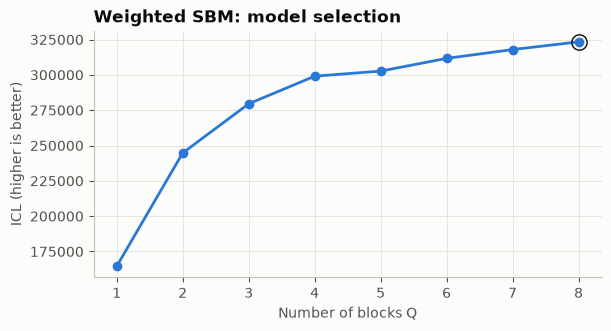

In [4]:
sel_g, fits_g = select_sbm(D, "gaussian")
display(sel_g.round(1))
Q_G = int(sel_g.loc[sel_g.ICL.idxmax(), "Q"])   # override by hand if you prefer another Q
z_g = fits_g[Q_G]
print(f"ICL chooses Q = {Q_G}; block sizes: {np.bincount(z_g).tolist()}")

fig, ax = plt.subplots(figsize=(6, 3.2), layout="constrained")
ax.plot(sel_g.Q, sel_g.ICL, marker="o", color=BLUE, lw=2, ms=6)
ax.plot(Q_G, sel_g.ICL.max(), marker="o", ms=11, mfc="none", mec=INK)
ax.set(xlabel="Number of blocks Q", ylabel="ICL (higher is better)", title="Weighted SBM: model selection",
       xticks=list(Q_RANGE))
fig.savefig(FIG / f"network_sbm_icl_k{K}_{YEAR}.png", dpi=160)
plt.show()

**Distance matrix sorted by block.** If the SBM fits, the matrix shows a block pattern: each tile has a roughly constant
shade. Lines mark block boundaries; the right panel is the fitted block-pair mean distance μ.

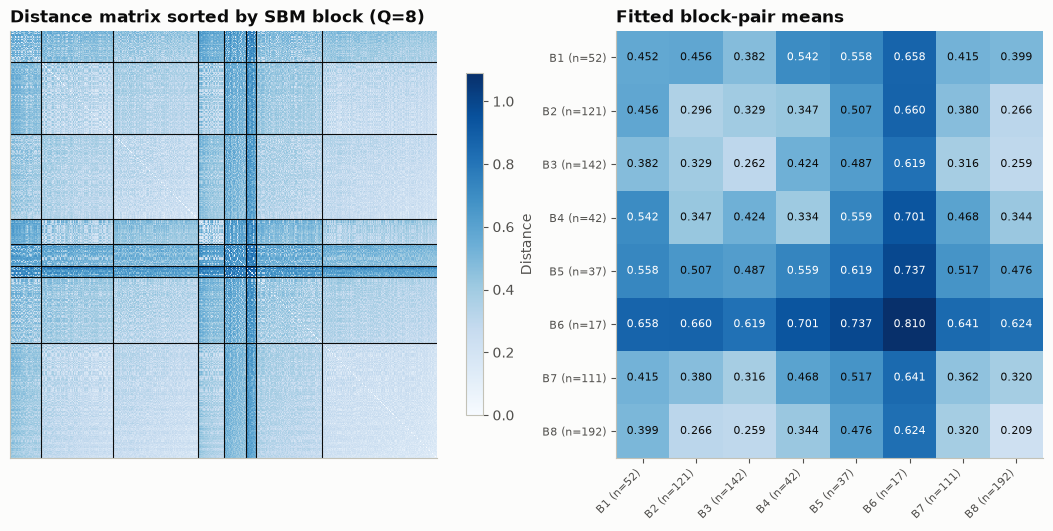

In [5]:
def block_means(M, z):
    Q = z.max() + 1
    out = np.zeros((Q, Q))
    for a in range(Q):
        for b in range(Q):
            sub = M[np.ix_(z == a, z == b)]
            out[a, b] = sub[~np.eye(*sub.shape, dtype=bool)].mean() if a == b and len(sub) > 1 else (sub.mean() if a != b else np.nan)
    return out

def plot_sorted(M, z, title, cmap, path, label):
    order = np.lexsort((-(M.sum(1)), z))
    sizes = np.bincount(z)
    fig, ax = plt.subplots(1, 2, figsize=(12, 5.2), layout="constrained", width_ratios=[1.25, 1])
    im = ax[0].imshow(M[np.ix_(order, order)], cmap=cmap, interpolation="nearest")
    for edge in np.cumsum(sizes)[:-1]:
        ax[0].axhline(edge - .5, color=INK, lw=.8); ax[0].axvline(edge - .5, color=INK, lw=.8)
    ax[0].set(title=title, xticks=[], yticks=[]); ax[0].grid(False)
    fig.colorbar(im, ax=ax[0], shrink=.8, label=label)
    mu = block_means(M, z)
    im2 = ax[1].imshow(mu, cmap=cmap, vmin=np.nanmin(M[M > 0]) if label.startswith("Dist") else 0, vmax=np.nanmax(mu))
    for a in range(len(mu)):
        for b in range(len(mu)):
            ax[1].text(b, a, f"{mu[a, b]:.3f}" if label.startswith("Dist") else f"{mu[a, b]:.2f}", ha="center",
                       va="center", fontsize=8, color="white" if mu[a, b] > np.nanmean(mu) * 1.15 else INK)
    ticks = [f"B{a + 1} (n={s})" for a, s in enumerate(sizes)]
    ax[1].set_xticks(range(len(sizes)), ticks, rotation=45, ha="right", fontsize=8)
    ax[1].set_yticks(range(len(sizes)), ticks, fontsize=8)
    ax[1].set_title("Fitted block-pair means"); ax[1].grid(False)
    fig.savefig(path, dpi=160)
    plt.show()

plot_sorted(D, z_g, f"Distance matrix sorted by SBM block (Q={Q_G})", "Blues", FIG / f"network_sbm_matrix_k{K}_{YEAR}.png",
            "Distance")

## 4. What distinguishes the blocks

**Topic profiles:** each block's mean topic weight minus the all-district mean (red = more of that topic than average,
blue = less). These are the topics driving the partition.

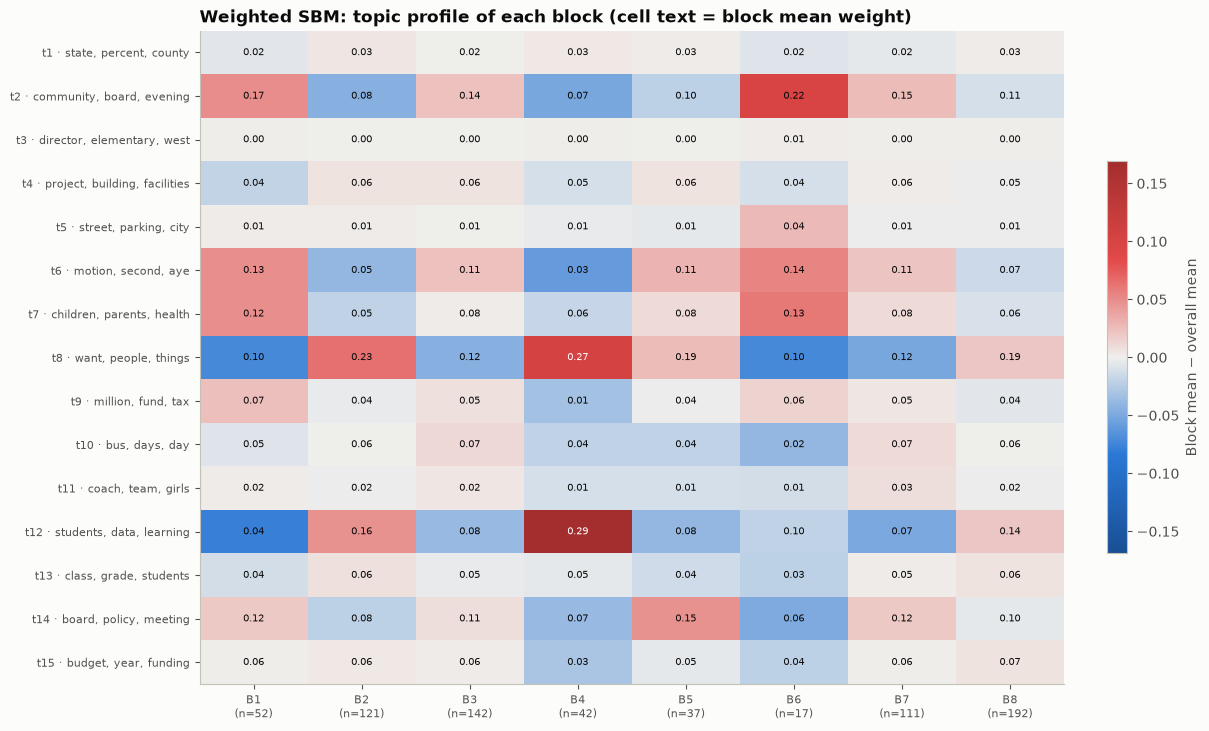

In [6]:
from matplotlib.colors import LinearSegmentedColormap
diverging = LinearSegmentedColormap.from_list("blue_gray_red", ["#184f95", "#2a78d6", "#f0efec", "#e34948", "#a32e2d"])

def plot_profiles(z, name, path):
    prof = profiles.groupby(z)[T].mean()
    dev = prof - profiles[T].mean()
    lim = np.abs(dev.values).max()
    fig, ax = plt.subplots(figsize=(.75 * len(prof) + 6, .38 * K + 1.5), layout="constrained")
    im = ax.imshow(dev.T.values, cmap=diverging, vmin=-lim, vmax=lim, aspect="auto")
    for a in range(len(prof)):
        for j in range(K):
            ax.text(a, j, f"{prof.iloc[a, j]:.2f}", ha="center", va="center", fontsize=7.5,
                    color="white" if abs(dev.iloc[a, j]) > .6 * lim else INK)
    sizes = np.bincount(z)
    ax.set_xticks(range(len(prof)), [f"B{a + 1}\n(n={s})" for a, s in enumerate(sizes)], fontsize=8)
    ax.set_yticks(range(K), [LABEL[t] for t in T], fontsize=8)
    ax.grid(False)
    fig.colorbar(im, ax=ax, shrink=.6, label="Block mean − overall mean")
    ax.set_title(f"{name}: topic profile of each block (cell text = block mean weight)")
    fig.savefig(path, dpi=160)
    plt.show()

plot_profiles(z_g, "Weighted SBM", FIG / f"network_sbm_profiles_k{K}_{YEAR}.png")

**District characteristics by block** (from `District Covariates/processed/district_static.parquet`): county 2020
two-party GOP vote share (the project's partisanship proxy), NCES locale, and number of meetings. If blocks line up with
partisanship or urbanicity, that is evidence that agendas cluster along those lines.

In [7]:
static = pd.read_parquet("Datastore/District Covariates/processed/district_static.parquet",
                         columns=["leaid", "lea_name", "state_location", "urban_centric_locale", "gop_2p_2020"])
static["leaid"] = static.leaid.astype(str).str.zfill(7)
LOCALE = {1: "City", 2: "Suburb", 3: "Town", 4: "Rural"}
static["locale"] = (pd.to_numeric(static.urban_centric_locale, errors="coerce") // 10).map(LOCALE)
dist = profiles[[]].reset_index().merge(static, on="leaid", how="left")
dist["meetings"] = n_meet.loc[dist.leaid].values
dist["block_weighted"] = z_g + 1
print(f"Covariate merge: {dist.lea_name.notna().mean():.1%} of districts matched; "
      f"GOP 2020 available for {dist.gop_2p_2020.notna().mean():.1%}")

def describe_blocks(col):
    g = dist.groupby(col)
    out = pd.DataFrame({
        "districts": g.size(),
        "median_meetings": g.meetings.median(),
        "gop_2p_2020_mean": g.gop_2p_2020.mean().round(3),
        "gop_2p_2020_median": g.gop_2p_2020.median().round(3),
        **{f"pct_{v.lower()}": g.locale.apply(lambda s, v=v: round((s == v).mean() * 100)) for v in LOCALE.values()},
        "top_states": g.state_location.agg(lambda s: ", ".join(s.value_counts().head(3).index)),
    })
    return out

display(describe_blocks("block_weighted"))

Covariate merge: 100.0% of districts matched; GOP 2020 available for 99.9%


,districts,median_meetings,gop_2p_2020_mean,gop_2p_2020_median,pct_city,pct_suburb,pct_town,pct_rural,top_states
block_weighted,,,,,,,,,
1,52,1.0,0.524,0.537,23,40,10,27,"OH, PA, SC"
2,121,1.0,0.489,0.452,18,41,19,21,"CA, NY, WI"
3,142,2.0,0.495,0.489,11,51,13,25,"CA, OH, NC"
4,42,1.0,0.470,0.455,40,31,10,19,"WA, WI, NY"
5,37,1.0,0.503,0.526,11,38,19,32,"OH, CA, IL"
6,17,1.0,0.449,0.417,35,41,18,6,"OH, NJ, NY"
7,111,1.0,0.504,0.475,18,40,18,24,"NY, PA, CA"
8,192,2.0,0.476,0.457,20,43,15,23,"CA, NY, OH"


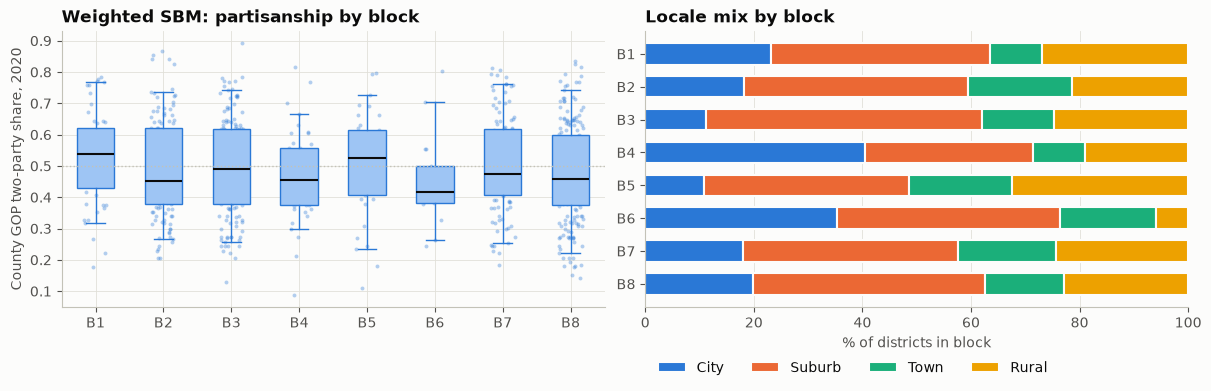

In [8]:
LOCALE_COLORS = {"City": "#2a78d6", "Suburb": "#eb6834", "Town": "#1baf7a", "Rural": "#eda100"}

def plot_covariates(col, name, path):
    blocks = sorted(dist[col].unique())
    fig, ax = plt.subplots(1, 2, figsize=(12, 3.8), layout="constrained")
    data = [dist.loc[dist[col] == b, "gop_2p_2020"].dropna() for b in blocks]
    ax[0].boxplot(data, whis=(5, 95), showfliers=False, widths=.55, patch_artist=True,
                  boxprops=dict(facecolor=BLUE_LIGHT, edgecolor=BLUE), medianprops=dict(color=INK, lw=1.5),
                  whiskerprops=dict(color=BLUE), capprops=dict(color=BLUE))
    rng = np.random.default_rng(SEED)
    for k, v in enumerate(data, start=1):
        ax[0].scatter(k + rng.uniform(-.18, .18, len(v)), v, s=8, color=BLUE, alpha=.35, lw=0)
    ax[0].axhline(.5, color=GRAY, lw=1, ls=":")
    ax[0].set_xticks(range(1, len(blocks) + 1), [f"B{b}" for b in blocks])
    ax[0].set(ylabel="County GOP two-party share, 2020", title=f"{name}: partisanship by block")
    comp = pd.crosstab(dist[col], dist.locale, normalize="index").reindex(columns=list(LOCALE.values()), fill_value=0) * 100
    left = np.zeros(len(comp))
    for loc_name in comp.columns:
        ax[1].barh([f"B{b}" for b in comp.index], comp[loc_name], left=left, color=LOCALE_COLORS[loc_name],
                   edgecolor="#fcfcfb", lw=1.5, label=loc_name, height=.65)
        left += comp[loc_name].values
    ax[1].invert_yaxis()
    ax[1].set(xlabel="% of districts in block", xlim=(0, 100), title="Locale mix by block")
    ax[1].legend(ncol=4, loc="upper left", bbox_to_anchor=(0, -.15), frameon=False)
    ax[1].grid(axis="y", visible=False)
    fig.savefig(path, dpi=160)
    plt.show()

plot_covariates("block_weighted", "Weighted SBM", FIG / f"network_sbm_covariates_k{K}_{YEAR}.png")

## 5. Comparison: Bernoulli SBM on a k-nearest-neighbour graph

Turn distances into a binary network: districts `i` and `j` are linked if `j` is among `i`'s `KNN` closest districts or
vice versa. Then fit the classic Bernoulli SBM with the same code. The adjusted Rand index (ARI) measures agreement with
the weighted-SBM partition (1 = identical, 0 = chance).

kNN graph: 5,137 edges, density 0.020, mean degree 14.4


,Q,loglik,ICL,smallest_block,seconds
0,1,-25134.5,-25140.7,714,0.0
1,2,-23308.6,-23822.3,323,1.2
2,3,-22160.0,-22958.2,146,2.2
3,4,-21253.9,-22285.8,118,2.3
4,5,-20774.0,-21981.0,90,4.1
5,6,-20272.2,-21675.2,78,5.2
6,7,-19810.7,-21349.3,57,7.1
7,8,-19488.7,-21162.2,48,9.1


ICL chooses Q = 8; block sizes: [56, 128, 73, 75, 60, 120, 48, 154]
Agreement with weighted SBM: ARI = 0.12


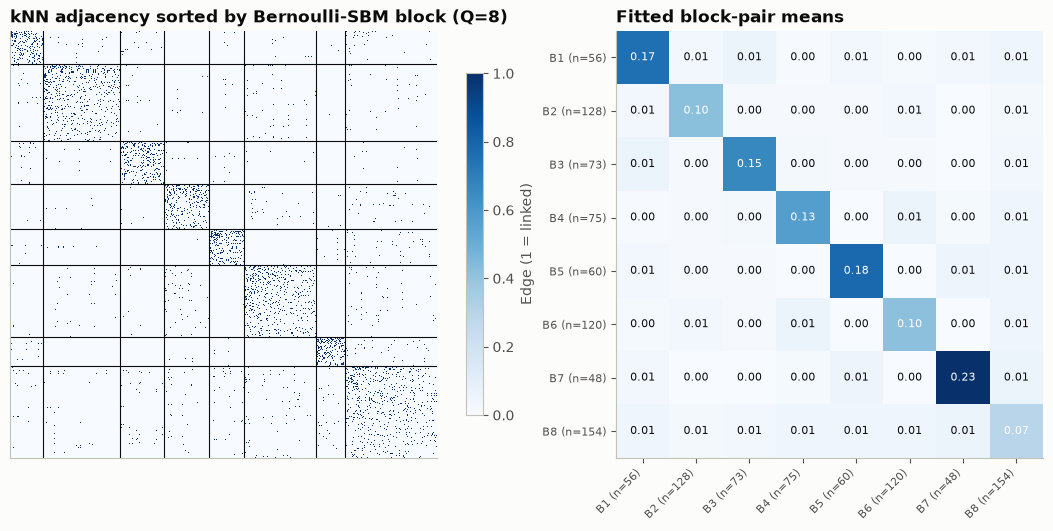

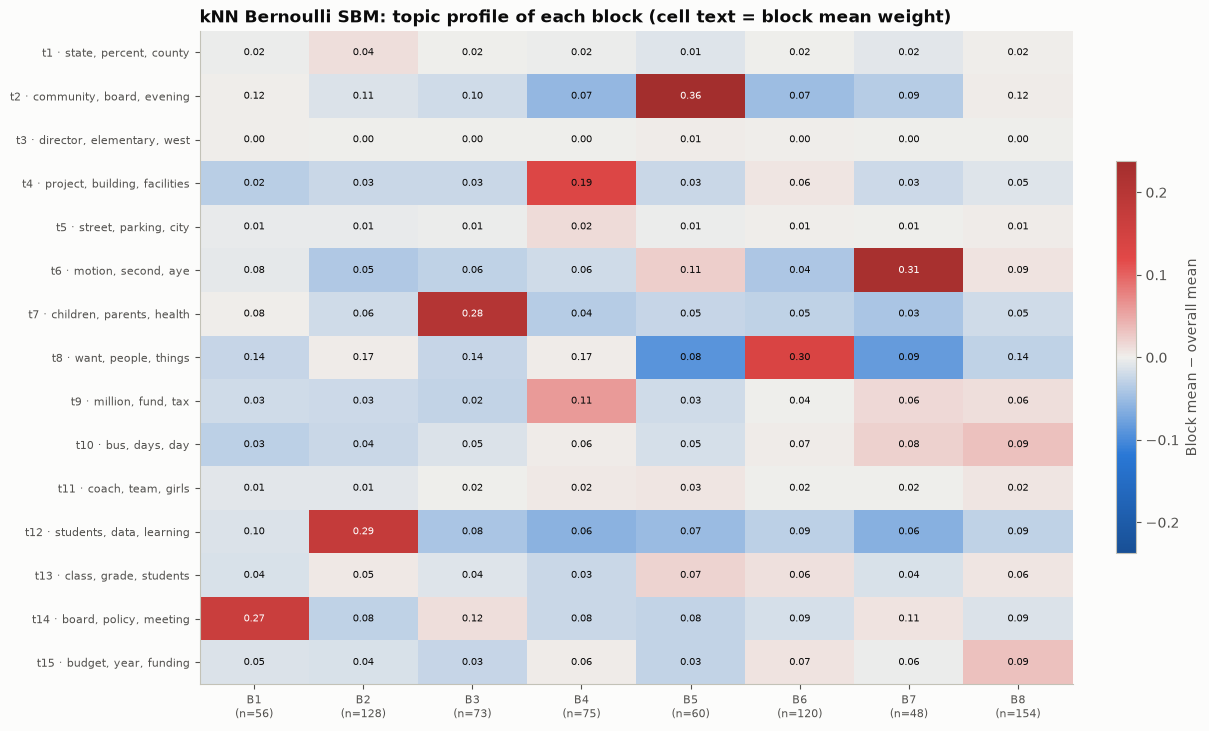

,districts,median_meetings,gop_2p_2020_mean,gop_2p_2020_median,pct_city,pct_suburb,pct_town,pct_rural,top_states
block_knn,,,,,,,,,
1,56,1.5,0.442,0.419,29,55,5,11,"NY, NJ, WI"
2,128,1.0,0.439,0.443,32,47,9,12,"NY, CA, IL"
3,73,1.0,0.471,0.486,11,53,12,23,"CA, NY, OH"
4,75,1.0,0.508,0.500,16,39,17,28,"CA, NY, NC"
5,60,1.0,0.452,0.453,35,48,8,8,"CA, NY, NJ"
6,120,2.0,0.512,0.482,10,34,23,32,"NY, CA, WI"
7,48,1.5,0.567,0.568,8,29,27,35,"NY, OH, IN"
8,154,2.0,0.525,0.513,14,39,17,31,"OH, CA, TX"


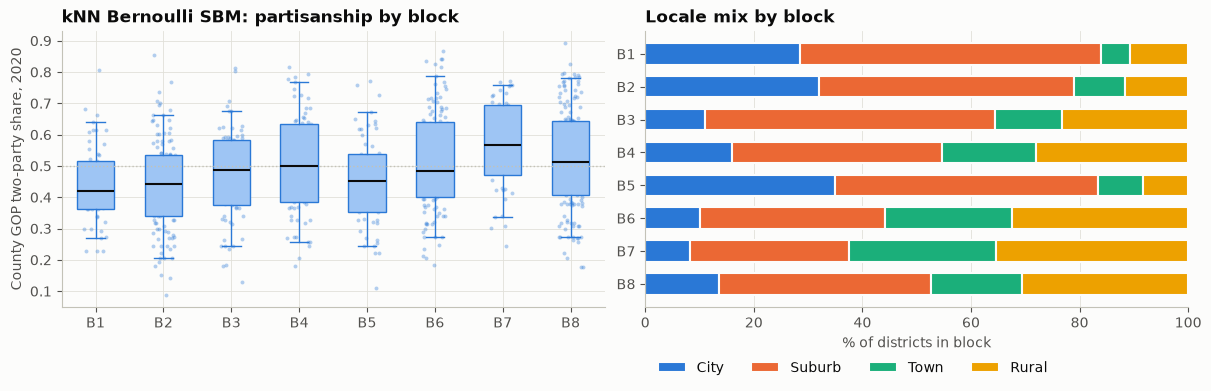

In [9]:
nearest = np.argsort(D + np.diag(np.full(n, np.inf)), axis=1)[:, :KNN]
A = np.zeros((n, n))
A[np.repeat(np.arange(n), KNN), nearest.ravel()] = 1
A = np.maximum(A, A.T)
np.fill_diagonal(A, 0)
print(f"kNN graph: {int(A.sum() / 2):,} edges, density {A.sum() / (n * (n - 1)):.3f}, mean degree {A.sum(1).mean():.1f}")

sel_b, fits_b = select_sbm(A, "bernoulli")
display(sel_b.round(1))
Q_B = int(sel_b.loc[sel_b.ICL.idxmax(), "Q"])
z_b = fits_b[Q_B]
dist["block_knn"] = z_b + 1
print(f"ICL chooses Q = {Q_B}; block sizes: {np.bincount(z_b).tolist()}")
print(f"Agreement with weighted SBM: ARI = {adjusted_rand_score(z_g, z_b):.2f}")

plot_sorted(A, z_b, f"kNN adjacency sorted by Bernoulli-SBM block (Q={Q_B})", "Blues",
            FIG / f"network_knn_sbm_matrix_k{K}_{YEAR}.png", "Edge (1 = linked)")
plot_profiles(z_b, "kNN Bernoulli SBM", FIG / f"network_knn_sbm_profiles_k{K}_{YEAR}.png")
display(describe_blocks("block_knn"))
plot_covariates("block_knn", "kNN Bernoulli SBM", FIG / f"network_knn_sbm_covariates_k{K}_{YEAR}.png")

## 6. Save block assignments
One row per district: topic profile, number of meetings, both block labels and covariates — for later analysis
(e.g. comparing 2018–19 and 2022–23 networks once the full data are in).

In [ ]:
out = dist.merge(profiles.reset_index(), on="leaid")
path = RES / f"sbm_blocks_k{K}_{YEAR}.csv"
out.to_csv(path, index=False)
print("Saved", path, out.shape)